In [10]:
import pandas as pd
import numpy as np

# 1️⃣ 读取数据（根据你的文件类型选择）
df = pd.read_csv('application_data.csv')

# 1. 不把 ID 和 TARGET 放进 FAMD
drop_cols = ['SK_ID_CURR', 'TARGET']
X = df.drop(columns=drop_cols)

# 2. 找 categorical columns
cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

# binary 数值变量也更适合当 categorical
binary_cols = [
    col for col in num_cols
    if X[col].nunique(dropna=True) == 2
]

# 从 numerical 中移除 binary
num_cols = [col for col in num_cols if col not in binary_cols]

# 2. 统计 numerical 缺失比例
num_missing_ratio = X[num_cols].isnull().mean().sort_values(ascending=False)

missing_summary = pd.DataFrame({
    "missing_count": X[num_cols].isnull().sum(),
    "missing_ratio": X[num_cols].isnull().mean()
}).sort_values("missing_ratio", ascending=False)

print(missing_summary.head(30))

# 按缺失比例分组
low_missing_num = num_missing_ratio[num_missing_ratio < 0.05].index.tolist()

mid_missing_num = num_missing_ratio[
    (num_missing_ratio >= 0.05) & 
    (num_missing_ratio <= 0.40)
].index.tolist()

high_missing_num = num_missing_ratio[num_missing_ratio > 0.40].index.tolist()

print("Low missing numerical:", len(low_missing_num))
print("Mid missing numerical:", len(mid_missing_num))
print("High missing numerical:", len(high_missing_num))

# 3. 处理异常类别
X_processed = X.copy()

for col in cat_cols:
    X_processed[col] = X_processed[col].replace({
        "XNA": "Missing",
        "Unknown": "Missing",
        "XAP": "Missing"
    })
    X_processed[col] = X_processed[col].fillna("Missing")
    X_processed[col] = X_processed[col].astype("category")


# 4. binary variables 当 categorical
for col in binary_cols:
    X_processed[col] = X_processed[col].fillna("Missing")
    X_processed[col] = X_processed[col].astype("category")


                          missing_count  missing_ratio
COMMONAREA_MODE                  214865       0.698723
COMMONAREA_MEDI                  214865       0.698723
COMMONAREA_AVG                   214865       0.698723
NONLIVINGAPARTMENTS_AVG          213514       0.694330
NONLIVINGAPARTMENTS_MEDI         213514       0.694330
NONLIVINGAPARTMENTS_MODE         213514       0.694330
LIVINGAPARTMENTS_AVG             210199       0.683550
LIVINGAPARTMENTS_MODE            210199       0.683550
LIVINGAPARTMENTS_MEDI            210199       0.683550
FLOORSMIN_AVG                    208642       0.678486
FLOORSMIN_MODE                   208642       0.678486
FLOORSMIN_MEDI                   208642       0.678486
YEARS_BUILD_MEDI                 204488       0.664978
YEARS_BUILD_AVG                  204488       0.664978
YEARS_BUILD_MODE                 204488       0.664978
OWN_CAR_AGE                      202929       0.659908
LANDAREA_AVG                     182590       0.593767
LANDAREA_M

In [11]:
# 5. low missing numerical: median
# =========================

for col in low_missing_num:
    X_processed[col] = X_processed[col].fillna(X_processed[col].median())


# =========================
# 6. mid missing numerical: median + missing flag
# =========================

for col in mid_missing_num:
    X_processed[col + "_missing_flag"] = X_processed[col].isnull().astype("category")
    X_processed[col] = X_processed[col].fillna(X_processed[col].median())


# =========================
# 7. high missing numerical: 转 categorical，不 drop
# =========================

for col in high_missing_num:
    X_processed[col] = X_processed[col].astype("object")
    X_processed[col] = X_processed[col].fillna("Missing")
    X_processed[col] = X_processed[col].astype("category")


In [12]:
print(X_processed.isnull().sum().sum())

print(X_processed.dtypes.value_counts())



0
category    32
float64     20
int64        7
category     7
category     2
            ..
category     1
category     1
category     1
category     1
category     1
Name: count, Length: 63, dtype: int64


In [13]:
X_processed.to_csv("X_processed.csv", index=False)

# Previous 

In [14]:
# ============================================================
# previous_application 的处理
# 区别：
# 1. 使用 X_prev / X_prev_processed，与 application_data 的 X / X_processed 区分
# 2. previous_application 的特征列统一加 PREV_ 前缀
# 3. 指定的 DAYS_* 变量只做 median 填充，不做 indicator，也不转 categorical
# ============================================================

df_prev = pd.read_csv("previous_application.csv")

# previous_application 里 SK_ID_PREV 和 SK_ID_CURR 都不参与 FAMD 特征处理
prev_id_cols = [col for col in ["SK_ID_PREV", "SK_ID_CURR"] if col in df_prev.columns]

X_prev = df_prev.drop(columns=prev_id_cols)

# 计算所有列的缺失比例
prev_missing_ratio_all = X_prev.isnull().mean().sort_values(ascending=False)

high_missing_80_cols = prev_missing_ratio_all[
    prev_missing_ratio_all > 0.8
].index.tolist()

print("Number of features >80% missing:", len(high_missing_80_cols))
print(high_missing_80_cols)

X_prev = X_prev.drop(columns=high_missing_80_cols)

print("Shape after dropping >80% missing:", X_prev.shape)

Number of features >80% missing: 2
['RATE_INTEREST_PRIVILEGED', 'RATE_INTEREST_PRIMARY']
Shape after dropping >80% missing: (1670214, 33)


In [15]:
# 这几列按照你的要求：只 median 填充
special_median_cols = [
    "DAYS_FIRST_DRAWING",
    "DAYS_FIRST_DUE",
    "DAYS_LAST_DUE_1ST_VERSION",
    "DAYS_LAST_DUE",
    "DAYS_TERMINATION"
]

special_median_cols = [
    col for col in special_median_cols
    if col in X_prev.columns
]

# 1. 找 categorical / numerical
prev_cat_cols = X_prev.select_dtypes(include="object").columns.tolist()
prev_num_cols = X_prev.select_dtypes(include=["int64", "float64"]).columns.tolist()

# 2. binary numerical variables 当 categorical
# 注意：special_median_cols 不参与 binary 转 categorical
prev_binary_cols = [
    col for col in prev_num_cols
    if col not in special_median_cols
    and X_prev[col].nunique(dropna=True) == 2
]

# 3. 剩下真正按缺失比例处理的 numerical
prev_num_cols_for_missing_rule = [
    col for col in prev_num_cols
    if col not in prev_binary_cols
    and col not in special_median_cols
]

# 4. 统计 numerical 缺失比例
prev_num_missing_ratio = (
    X_prev[prev_num_cols_for_missing_rule]
    .isnull()
    .mean()
    .sort_values(ascending=False)
)

prev_missing_summary = pd.DataFrame({
    "missing_count": X_prev[prev_num_cols_for_missing_rule].isnull().sum(),
    "missing_ratio": X_prev[prev_num_cols_for_missing_rule].isnull().mean()
}).sort_values("missing_ratio", ascending=False)

print("previous_application numerical missing summary:")
print(prev_missing_summary.head(30))

# 5. 按缺失比例分组
prev_low_missing_num = prev_num_missing_ratio[
    prev_num_missing_ratio < 0.05
].index.tolist()

prev_mid_missing_num = prev_num_missing_ratio[
    (prev_num_missing_ratio >= 0.05) &
    (prev_num_missing_ratio <= 0.40)
].index.tolist()

prev_high_missing_num = prev_num_missing_ratio[
    prev_num_missing_ratio > 0.40
].index.tolist()

print("Previous low missing numerical:", len(prev_low_missing_num))
print("Previous mid missing numerical:", len(prev_mid_missing_num))
print("Previous high missing numerical:", len(prev_high_missing_num))
print("Previous special median-only columns:", special_median_cols)

# ============================================================
# 开始处理 previous_application
# ============================================================

X_prev_processed = X_prev.copy()

# 6. categorical variables: Missing 作为类别保留
for col in prev_cat_cols:
    X_prev_processed[col] = X_prev_processed[col].replace({
        "XNA": "Missing",
        "Unknown": "Missing",
        "XAP": "Missing"
    })
    X_prev_processed[col] = X_prev_processed[col].fillna("Missing")
    X_prev_processed[col] = X_prev_processed[col].astype("category")

# 7. binary variables: 当 categorical
for col in prev_binary_cols:
    X_prev_processed[col] = X_prev_processed[col].astype("object")
    X_prev_processed[col] = X_prev_processed[col].fillna("Missing")
    X_prev_processed[col] = X_prev_processed[col].astype("category")

# 8. special DAYS columns: 只 median 填充，不 indicator，不 categorical
for col in special_median_cols:
    X_prev_processed[col] = X_prev_processed[col].fillna(X_prev_processed[col].median())

# 9. low missing numerical: median
for col in prev_low_missing_num:
    X_prev_processed[col] = X_prev_processed[col].fillna(X_prev_processed[col].median())

# 10. mid missing numerical: median + missing flag
for col in prev_mid_missing_num:
    X_prev_processed[col + "_missing_flag"] = X_prev_processed[col].isnull().astype("category")
    X_prev_processed[col] = X_prev_processed[col].fillna(X_prev_processed[col].median())

# 11. high missing numerical: 转 categorical，不 drop
for col in prev_high_missing_num:
    X_prev_processed[col] = X_prev_processed[col].astype("object")
    X_prev_processed[col] = X_prev_processed[col].fillna("Missing")
    X_prev_processed[col] = X_prev_processed[col].astype("category")

# ============================================================
# 加 PREV_ 标记，避免和 application_data 的 X_processed 混淆
# ============================================================

X_prev_processed = X_prev_processed.rename(
    columns={col: "PREV_" + col for col in X_prev_processed.columns}
)

# ID 列不加 PREV_，方便之后根据 SK_ID_CURR merge / aggregate
previous_processed_for_famd = pd.concat(
    [
        df_prev[prev_id_cols].reset_index(drop=True),
        X_prev_processed.reset_index(drop=True)
    ],
    axis=1
)

# 检查
print("Remaining missing values in previous_processed_for_famd:",
      previous_processed_for_famd.isnull().sum().sum())

print(previous_processed_for_famd.dtypes.value_counts())

# 保存处理后的 previous_application
# previous_processed_for_famd.to_csv(
#     "previous_application_processed_for_famd.csv",
#     index=False
# )

previous_processed_for_famd.head()


previous_application numerical missing summary:
                         missing_count  missing_ratio
RATE_DOWN_PAYMENT               895844   5.363648e-01
AMT_DOWN_PAYMENT                895844   5.363648e-01
AMT_GOODS_PRICE                 385515   2.308177e-01
AMT_ANNUITY                     372235   2.228667e-01
CNT_PAYMENT                     372230   2.228637e-01
AMT_CREDIT                           1   5.987257e-07
AMT_APPLICATION                      0   0.000000e+00
HOUR_APPR_PROCESS_START              0   0.000000e+00
DAYS_DECISION                        0   0.000000e+00
SELLERPLACE_AREA                     0   0.000000e+00
Previous low missing numerical: 5
Previous mid missing numerical: 3
Previous high missing numerical: 2
Previous special median-only columns: ['DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION']


C:\Users\rmoch\AppData\Local\Temp\ipykernel_37884\551027535.py:88: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_prev_processed[col] = X_prev_processed[col].fillna("Missing")


Remaining missing values in previous_processed_for_famd: 0
float64     10
int64        5
category     3
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
Name: count, dtype: int64


,SK_ID_PREV,SK_ID_CURR,PREV_NAME_CONTRACT_TYPE,PREV_AMT_ANNUITY,PREV_AMT_APPLICATION,PREV_AMT_CREDIT,PREV_AMT_DOWN_PAYMENT,PREV_AMT_GOODS_PRICE,PREV_WEEKDAY_APPR_PROCESS_START,PREV_HOUR_APPR_PROCESS_START,...,PREV_PRODUCT_COMBINATION,PREV_DAYS_FIRST_DRAWING,PREV_DAYS_FIRST_DUE,PREV_DAYS_LAST_DUE_1ST_VERSION,PREV_DAYS_LAST_DUE,PREV_DAYS_TERMINATION,PREV_NFLAG_INSURED_ON_APPROVAL,PREV_AMT_GOODS_PRICE_missing_flag,PREV_AMT_ANNUITY_missing_flag,PREV_CNT_PAYMENT_missing_flag
0,2030495,271877,Consumer loans,1730.430,17145.0,17145.0,0.0,17145.0,SATURDAY,15,...,POS mobile with interest,365243.0,-42.0,300.0,-42.0,-37.0,0.0,False,False,False
1,2802425,108129,Cash loans,25188.615,607500.0,679671.0,Missing,607500.0,THURSDAY,11,...,Cash X-Sell: low,365243.0,-134.0,916.0,365243.0,365243.0,1.0,False,False,False
2,2523466,122040,Cash loans,15060.735,112500.0,136444.5,Missing,112500.0,TUESDAY,11,...,Cash X-Sell: high,365243.0,-271.0,59.0,365243.0,365243.0,1.0,False,False,False
3,2819243,176158,Cash loans,47041.335,450000.0,470790.0,Missing,450000.0,MONDAY,7,...,Cash X-Sell: middle,365243.0,-482.0,-152.0,-182.0,-177.0,1.0,False,False,False
4,1784265,202054,Cash loans,31924.395,337500.0,404055.0,Missing,337500.0,THURSDAY,9,...,Cash Street: high,365243.0,-831.0,-361.0,-537.0,-499.0,Missing,False,False,False


# Merge

In [16]:
# =========================
# 1. application_data 加回 ID 和 TARGET
# =========================

app_for_merge = pd.concat(
    [
        df[["SK_ID_CURR", "TARGET"]].reset_index(drop=True),
        X_processed.reset_index(drop=True)
    ],
    axis=1
)

# =========================
# 2. previous_application 准备聚合
# =========================

prev = previous_processed_for_famd.copy()

# 不参与聚合的 ID
prev_id_cols = ["SK_ID_PREV", "SK_ID_CURR"]
prev_feature_cols = [
    col for col in prev.columns 
    if col not in prev_id_cols
]

# =========================
# 3. 区分 previous 中的 numerical / categorical
# =========================

prev_num_cols = prev[prev_feature_cols].select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

prev_cat_cols = prev[prev_feature_cols].select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()



# numerical previous：用统计量聚合
prev_num_agg = prev.groupby("SK_ID_CURR")[prev_num_cols].agg(
    ["mean", "median", "max", "min", "std"]
)

prev_num_agg.columns = [
    f"{col}_{stat}" for col, stat in prev_num_agg.columns
]

prev_num_agg = prev_num_agg.reset_index()



# categorical previous：用 mode + nunique 聚合
def mode_func(x):
    mode_value = x.mode(dropna=True)
    if len(mode_value) == 0:
        return "Missing"
    return mode_value.iloc[0]

prev_cat_mode = prev.groupby("SK_ID_CURR")[prev_cat_cols].agg(mode_func)

prev_cat_mode.columns = [
    f"{col}_mode" for col in prev_cat_mode.columns
]

prev_cat_nunique = prev.groupby("SK_ID_CURR")[prev_cat_cols].nunique()

prev_cat_nunique.columns = [
    f"{col}_nunique" for col in prev_cat_nunique.columns
]

prev_cat_agg = pd.concat(
    [prev_cat_mode, prev_cat_nunique],
    axis=1
).reset_index()



# 加一个 previous 申请次数特征
prev_count = prev.groupby("SK_ID_CURR").size().reset_index(name="PREV_application_count")



# 合并 previous 聚合结果
prev_agg = prev_count.merge(
    prev_num_agg,
    on="SK_ID_CURR",
    how="left"
).merge(
    prev_cat_agg,
    on="SK_ID_CURR",
    how="left"
)


# 和 application_data 合并
merged_for_famd = app_for_merge.merge(
    prev_agg,
    on="SK_ID_CURR",
    how="left"
)

print(merged_for_famd.shape)


# 处理merge后产生的缺失
# previous 申请次数缺失说明没有 previous record
merged_for_famd["PREV_application_count"] = (
    merged_for_famd["PREV_application_count"]
    .fillna(0)
)

# numerical 缺失填 0 或 median
merged_num_cols = merged_for_famd.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

merged_num_cols = [
    col for col in merged_num_cols
    if col not in ["SK_ID_CURR", "TARGET"]
]

for col in merged_num_cols:
    merged_for_famd[col] = merged_for_famd[col].fillna(
        merged_for_famd[col].median()
    )

# categorical 缺失填 Missing
merged_cat_cols = merged_for_famd.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in merged_cat_cols:
    merged_for_famd[col] = (
        merged_for_famd[col]
        .astype("object")
        .fillna("Missing")
        .astype("category")
    )


# 检验FAMD可行性
# famd_input = merged_for_famd.drop(columns=["SK_ID_CURR", "TARGET"])

# print(famd_input.isnull().sum().sum())
# print(famd_input.dtypes.value_counts())
# If output is 0, then merged dataset could be FAMD.



(307511, 241)


C:\Users\rmoch\AppData\Local\Temp\ipykernel_37884\3349275397.py:137: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna("Missing")
C:\Users\rmoch\AppData\Local\Temp\ipykernel_37884\3349275397.py:137: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna("Missing")
C:\Users\rmoch\AppData\Local\Temp\ipykernel_37884\3349275397.py:137: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_optio

In [17]:
print("SK_ID_CURR" in merged_for_famd.columns)
print("TARGET" in merged_for_famd.columns)

print(merged_for_famd.shape)
print(merged_for_famd[["SK_ID_CURR", "TARGET"]].head())
print(merged_for_famd["TARGET"].value_counts(dropna=False))

True
True
(307511, 241)
   SK_ID_CURR  TARGET
0      100002       1
1      100003       0
2      100004       0
3      100006       0
4      100007       0
TARGET
0    282686
1     24825
Name: count, dtype: int64


In [18]:
print(merged_for_famd.isnull().sum().sum())

0


In [20]:
merged_for_famd.to_csv("data_merged.csv", index=False)

In [19]:
print("TARGET" in X_processed.columns)
print("SK_ID_CURR" in X_processed.columns)

False
False


# Some plots

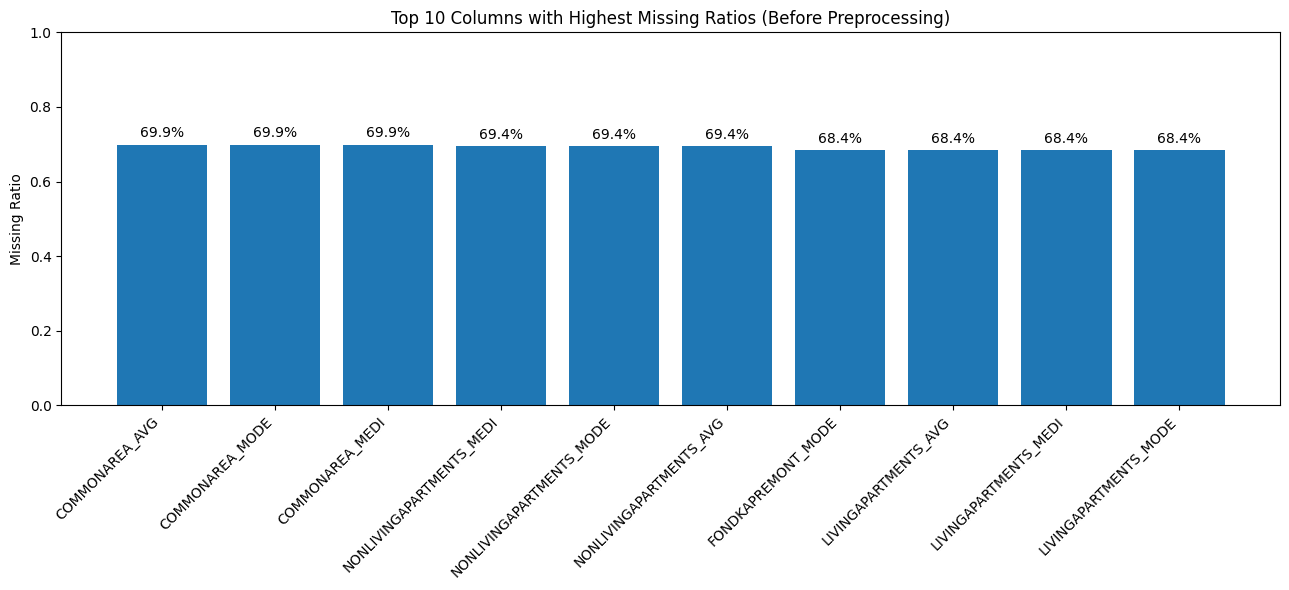

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

app_raw = pd.read_csv("application_data.csv")

missing_ratio = app_raw.isnull().mean().sort_values(ascending=False)
top10_missing = missing_ratio.head(10)

plt.figure(figsize=(13, 6))
bars = plt.bar(top10_missing.index, top10_missing.values)

plt.ylabel("Missing Ratio")
plt.title("Top 10 Columns with Highest Missing Ratios (Before Preprocessing)")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")

for i, v in enumerate(top10_missing.values):
    plt.text(i, v + 0.02, f"{v:.1%}", ha="center")

plt.tight_layout()
plt.show()

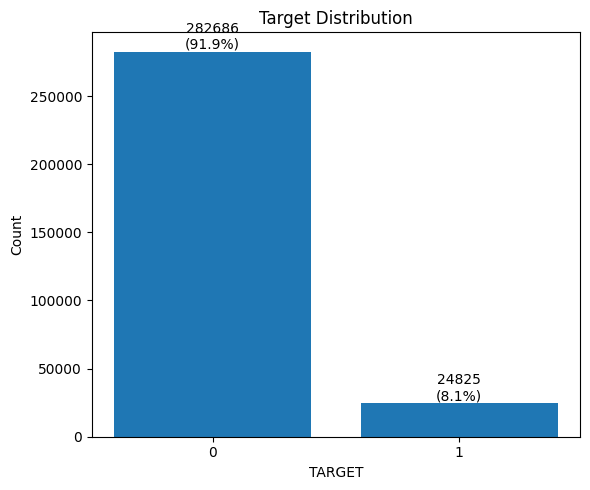

In [23]:
target_counts = app_raw["TARGET"].value_counts().sort_index()
target_ratio = app_raw["TARGET"].value_counts(normalize=True).sort_index()

plt.figure(figsize=(6, 5))
bars = plt.bar(target_counts.index.astype(str), target_counts.values)

plt.xlabel("TARGET")
plt.ylabel("Count")
plt.title("Target Distribution")

for i, (count, ratio) in enumerate(zip(target_counts.values, target_ratio.values)):
    plt.text(i, count + 2000, f"{count}\n({ratio:.1%})", ha="center")

plt.tight_layout()
plt.show()

                  Application Data  Previous Application
Numerical                       72                    17
Binary                          32                     2
Categorical                     16                    16
Contains XNA                     2                    10
Contains XAP                     0                     2
Contains Unknown                 1                     0


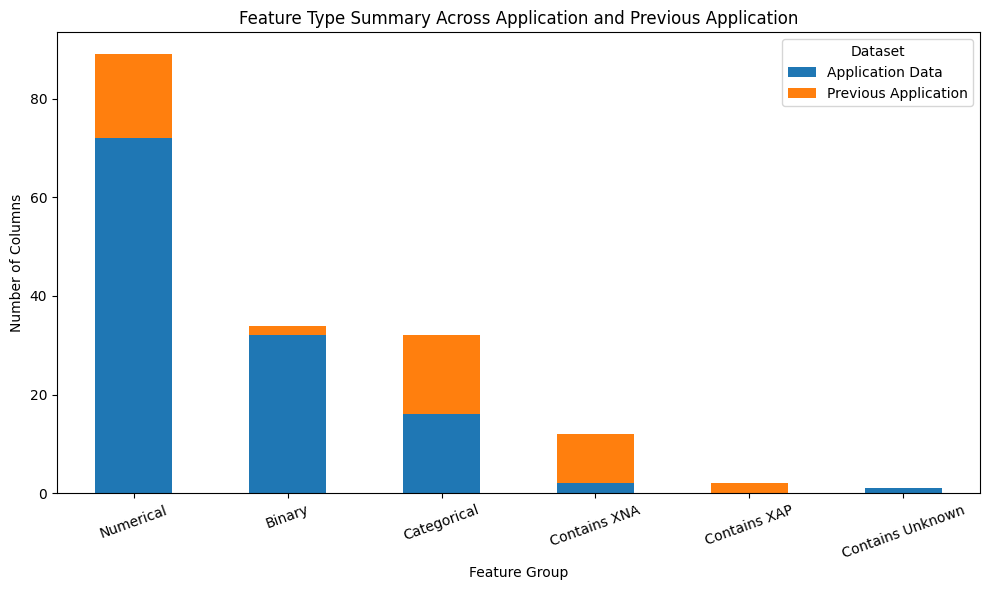

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# =========================
# 1. 读取数据
# =========================
app = pd.read_csv("application_data.csv")
prev = pd.read_csv("previous_application.csv")

# =========================
# 2. 写一个统计函数
# =========================
def summarize_feature_types(df, drop_cols=None):
    df_copy = df.copy()
    
    # 去掉不想统计的列
    if drop_cols is not None:
        existing_drop_cols = [col for col in drop_cols if col in df_copy.columns]
        df_copy = df_copy.drop(columns=existing_drop_cols)
    
    # categorical / numerical
    cat_cols = df_copy.select_dtypes(include="object").columns.tolist()
    num_cols = df_copy.select_dtypes(include=[np.number]).columns.tolist()
    
    # binary: 数值型中只有两个不同取值
    binary_cols = [
        col for col in num_cols
        if df_copy[col].nunique(dropna=True) == 2
    ]
    
    # 真正 numerical
    numerical_cols = [col for col in num_cols if col not in binary_cols]
    
    # 特殊值统计（只在 categorical 里找）
    xna_cols = [
        col for col in cat_cols
        if df_copy[col].astype(str).str.strip().str.upper().eq("XNA").any()
    ]
    
    xap_cols = [
        col for col in cat_cols
        if df_copy[col].astype(str).str.strip().str.upper().eq("XAP").any()
    ]
    
    unknown_cols = [
        col for col in cat_cols
        if df_copy[col].astype(str).str.strip().str.upper().eq("UNKNOWN").any()
    ]
    
    summary = pd.Series({
        "Numerical": len(numerical_cols),
        "Binary": len(binary_cols),
        "Categorical": len(cat_cols),
        "Contains XNA": len(xna_cols),
        "Contains XAP": len(xap_cols),
        "Contains Unknown": len(unknown_cols)
    })
    
    return summary

# =========================
# 3. 分别统计
# =========================
app_summary = summarize_feature_types(
    app,
    drop_cols=["SK_ID_CURR", "TARGET"]
)

prev_summary = summarize_feature_types(
    prev,
    drop_cols=["SK_ID_CURR", "SK_ID_PREV", "TARGET"]
)

# 合并成一个表
summary_df = pd.DataFrame({
    "Application Data": app_summary,
    "Previous Application": prev_summary
})

print(summary_df)

# =========================
# 4. 画 stacked bar chart
# =========================
ax = summary_df.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Feature Type Summary Across Application and Previous Application")
plt.xlabel("Feature Group")
plt.ylabel("Number of Columns")
plt.xticks(rotation=20)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

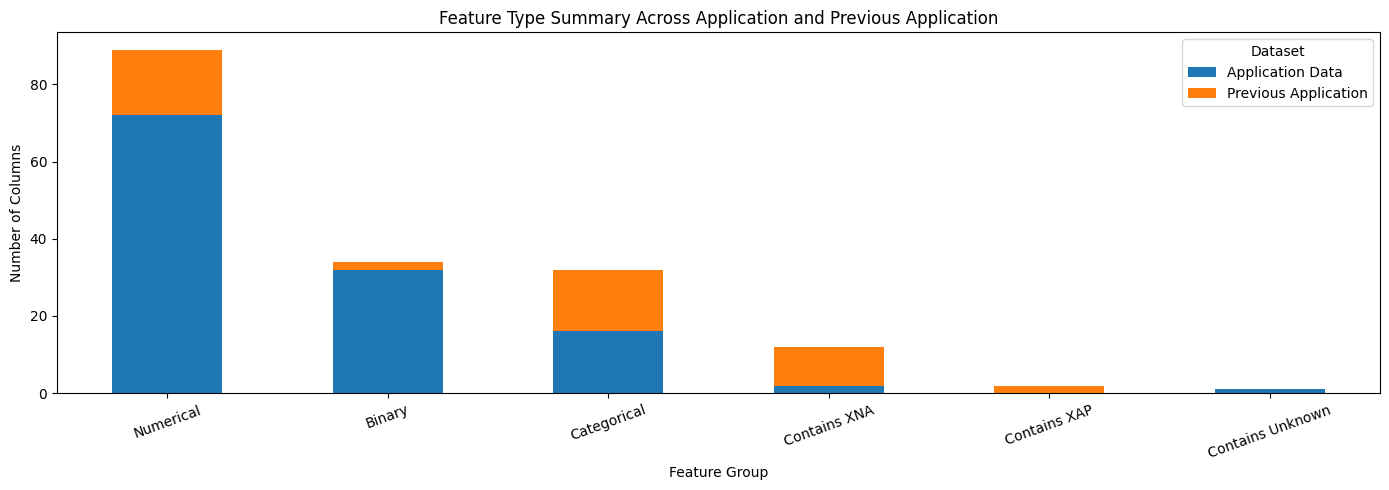

In [35]:
ax = summary_df.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 5)
)

plt.title("Feature Type Summary Across Application and Previous Application")
plt.xlabel("Feature Group")
plt.ylabel("Number of Columns")
plt.xticks(rotation=20)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()